# TCN — Fold 1 sonuçları

**Validation: Motor 2 · Eğitim: Motor 5, 10, 16, 18, 20**

Bu notebook kaydedilen `history.csv` ve **`best_model.pt`** dosyalarını okur.
Eğitim veya yeniden tahmin çalıştırmaz. Sonuçlar pencere bazındaki validation sonuçlarıdır.
RMSE birimi uçuş döngüsü, MSE birimi uçuş döngüsü²dir.

In [12]:
from pathlib import Path
from io import BytesIO
import math
import os
import tempfile

os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="tcn_results_"))

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, FileLink

# Repo kökünden veya notebooks klasöründen çalışır.
root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "n_cmapss").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError("Notebook'u proje klasörü içinde çalıştırın.")

# Raporun yanlışlıkla başka bir çalışmaya geçmemesi için açık çalışma seçimi.
run_name = "fold_1_20261119_220359_888340"
run_dir = root / "n_cmapss" / "outputs" / "tcn" / run_name
checkpoint_path = run_dir / "best_model.pt"
history = pd.read_csv(run_dir / "history.csv")
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

best_epoch = int(checkpoint["epoch"])
best_row = history.loc[history["epoch"] == best_epoch].iloc[0]
assert checkpoint["fold"] == 1
assert best_epoch == int(history.loc[history["validation_mse"].idxmin(), "epoch"])
assert math.isclose(checkpoint["validation_mse"], best_row["validation_mse"], rel_tol=1e-8)
assert math.isclose(checkpoint["validation_rmse"], best_row["validation_rmse"], rel_tol=1e-8)
print("Checkpoint ve eğitim geçmişi eşleşiyor.")

Checkpoint ve eğitim geçmişi eşleşiyor.


## En iyi model: best_model.pt

Bu dosya, en düşük validation MSE'nin görüldüğü epoch'un ağırlıklarını içerir.
Bir tablo dosyası değildir; aşağıda içindeki kayıtlı sonuç ve model bilgileri gösterilir.
Dosya bağlantısı VS Code'da açılmasa bile belirtilen konumdan bulunabilir.

In [13]:
display(Markdown(
    f"**En iyi epoch: {best_epoch} · Motor 2 validation RMSE: "
    f"{checkpoint['validation_rmse']:.4f} uçuş döngüsü**"
))
display(FileLink(os.path.relpath(checkpoint_path, Path.cwd())))
print("Dosya konumu:", checkpoint_path)

summary = pd.DataFrame([
    ("Dosya", checkpoint_path.name),
    ("Dosya boyutu", f"{checkpoint_path.stat().st_size / 1024:.1f} KiB"),
    ("Fold / validation motoru", "1 / 2"),
    ("En iyi epoch", best_epoch),
    ("Validation MSE", f"{checkpoint['validation_mse']:.4f}"),
    ("Validation RMSE (uçuş döngüsü)", f"{checkpoint['validation_rmse']:.4f}"),
    ("Tamamlanan epoch", int(history['epoch'].max())),
    ("En iyi epoch'tan sonraki epoch sayısı", int(history['epoch'].max()) - best_epoch),
    ("Döngü süresi (veri hazırlama hariç)", f"{history['elapsed_seconds'].iloc[-1]:.2f} saniye"),
    ("Seed", checkpoint['seed']),
], columns=["Alan", "Değer"])
display(summary.style.hide(axis="index"))

**En iyi epoch: 32 · Motor 2 validation RMSE: 5.4717 uçuş döngüsü**

/Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance/n_cmapss/outputs/tcn/fold_1_20261119_220359_888340/best_model.pt

Dosya konumu: /Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance/n_cmapss/outputs/tcn/fold_1_20261119_220359_888340/best_model.pt


Alan,Değer
Dosya,best_model.pt
Dosya boyutu,524.3 KiB
Fold / validation motoru,1 / 2
En iyi epoch,32
Validation MSE,29.9398
Validation RMSE (uçuş döngüsü),5.4717
Tamamlanan epoch,52
En iyi epoch'tan sonraki epoch sayısı,20
Döngü süresi (veri hazırlama hariç),130.96 saniye
Seed,42


## Eğitim grafikleri

Yeşil işaret, `best_model.pt` dosyasının kaydedildiği epoch'u gösterir.
Eğitim kaybı dropout açıkken, validation kaybı dropout kapalıyken hesaplanır.

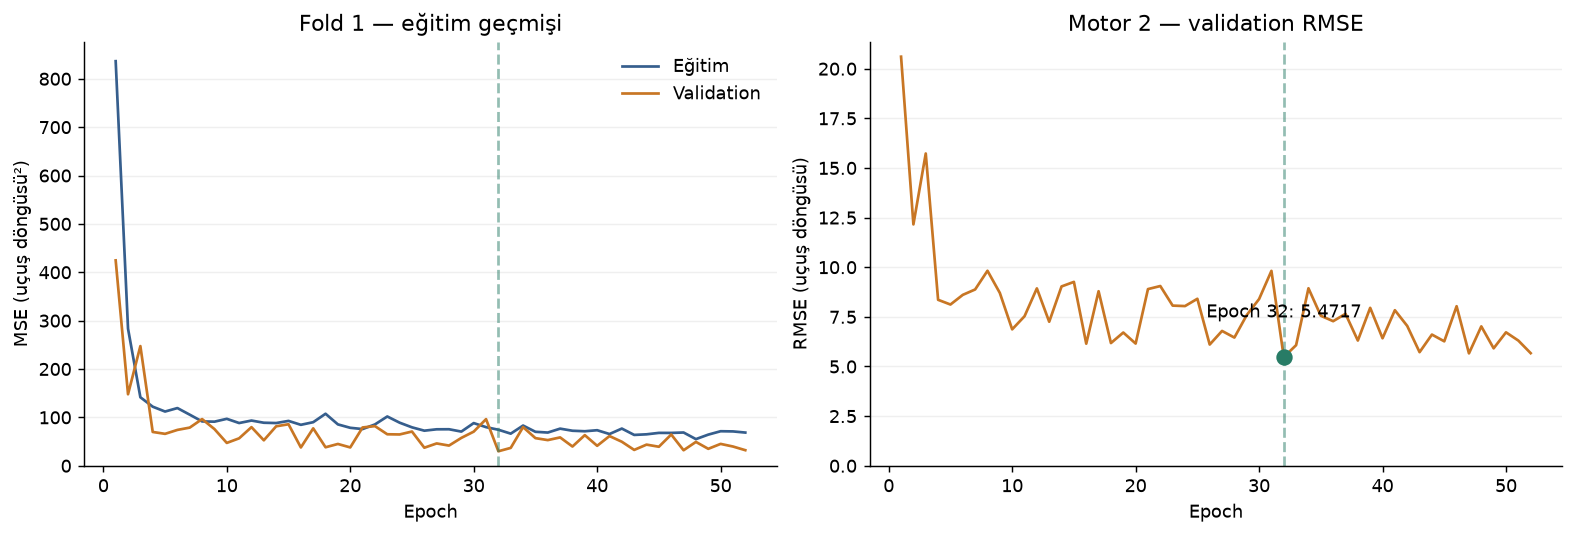

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(history.epoch, history.train_mse, label="Eğitim", color="#365E8D")
axes[0].plot(history.epoch, history.validation_mse, label="Validation", color="#C87624")
axes[0].set(title="Fold 1 — eğitim geçmişi", ylabel="MSE (uçuş döngüsü²)")
axes[0].legend(frameon=False)

axes[1].plot(history.epoch, history.validation_rmse, color="#C87624")
axes[1].scatter([best_epoch], [checkpoint['validation_rmse']], color="#287C66", s=65, zorder=3)
axes[1].annotate(
    f"Epoch {best_epoch}: {checkpoint['validation_rmse']:.4f}",
    (best_epoch, checkpoint['validation_rmse']),
    xytext=(0, 22), textcoords="offset points", ha="center",
)
axes[1].set(title="Motor 2 — validation RMSE", ylabel="RMSE (uçuş döngüsü)")
for ax in axes:
    ax.axvline(best_epoch, linestyle="--", color="#287C66", alpha=0.5)
    ax.set_xlabel("Epoch")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Epoch tablosu

`is_best=True`, o epoch'ta o ana kadarki en iyi modelin kaydedildiğini belirtir.
Dosyada kalan model, bunların sonuncusudur.

In [15]:
display(history.style.hide(axis="index").format({
    "train_mse": "{:.4f}", "validation_mse": "{:.4f}",
    "validation_rmse": "{:.4f}", "epoch_seconds": "{:.2f}",
    "elapsed_seconds": "{:.2f}",
}).apply(
    lambda row: ["background-color: #e2f0e8" if row["epoch"] == best_epoch else ""] * len(row),
    axis=1,
))

epoch,train_mse,validation_mse,validation_rmse,epoch_seconds,elapsed_seconds,is_best
1,836.4142,424.5598,20.6049,3.47,3.49,True
2,283.3972,147.7932,12.1570,2.48,5.98,True
3,141.5412,247.3804,15.7283,2.52,8.49,False
4,122.1050,69.8690,8.3588,2.50,11.00,True
5,112.0526,65.9528,8.1211,2.49,13.51,True
6,119.2353,74.0835,8.6072,2.49,16.00,False
7,105.5484,78.8490,8.8797,2.50,18.50,False
8,91.6301,96.4621,9.8215,2.48,20.98,False
9,91.1276,75.7998,8.7063,2.45,23.42,False
10,97.0174,47.1973,6.8700,2.46,25.90,True


## Checkpoint içeriği

Ağırlıkların tamamını sayılarla dökmek yerine katman adları ve tensör boyutları gösterilir.
Checkpoint ayrıca model ayarlarını, özellik sırasını ve standardizasyon için ortalama/ölçek
değerlerini saklar. Aşağıdakiler dosyadan okunur; model sınıfı import edilmez.

In [16]:
display(pd.DataFrame([
    {"Ayar": key, "Değer": str(value)}
    for key, value in checkpoint["model_config"].items()
]).style.hide(axis="index"))

weights = pd.DataFrame([
    {"Katman / tensör": name, "Boyut": str(tuple(tensor.shape)), "Eleman sayısı": tensor.numel()}
    for name, tensor in checkpoint["model_state_dict"].items()
])
display(weights.style.hide(axis="index"))
display(pd.DataFrame({
    "Özellik": checkpoint["feature_names"],
    "Eğitim ortalaması": checkpoint["scaler_mean"],
    "Eğitim ölçeği": checkpoint["scaler_scale"],
}).style.hide(axis="index").format({
    "Eğitim ortalaması": "{:.4f}", "Eğitim ölçeği": "{:.4f}"
}))

Ayar,Değer
input_channels,18
channels,"(32, 32, 64, 64, 64, 64, 64)"
kernel_size,3
dropout,0.2


Katman / tensör,Boyut,Eleman sayısı
backbone.0.network.0.conv.weight,"(32, 18, 3)",1728
backbone.0.network.0.conv.bias,"(32,)",32
backbone.0.network.3.conv.weight,"(32, 32, 3)",3072
backbone.0.network.3.conv.bias,"(32,)",32
backbone.0.residual.weight,"(32, 18, 1)",576
backbone.0.residual.bias,"(32,)",32
backbone.1.network.0.conv.weight,"(32, 32, 3)",3072
backbone.1.network.0.conv.bias,"(32,)",32
backbone.1.network.3.conv.weight,"(32, 32, 3)",3072
backbone.1.network.3.conv.bias,"(32,)",32


Özellik,Eğitim ortalaması,Eğitim ölçeği
alt,21579.7309,6514.7688
Mach,0.6199,0.0819
TRA,69.0117,13.8492
T2,475.8264,17.0817
T24,560.5068,19.2645
T30,1323.8613,57.8000
T48,1649.9796,99.8546
T50,1110.4075,55.6988
P15,10.9779,2.3091
P2,8.3376,1.8379


## TCN baseline — Model ve deney konfigürasyonu

Model, bir uçuş içinden seçilen 256 ardışık zaman adımındaki 18 özelliği kullanarak
pencere başına bir RUL tahmini üretir. Hedef birimi kalan uçuş döngüsüdür.

| Ayar | Baseline değeri |
|---|---|
| Mimari | 7 residual blok; her blokta 2 nedensel Conv1d katmanı |
| Blok çıkış kanalları | 32, 32, 64, 64, 64, 64, 64 |
| Kernel size | 3 |
| Blokların dilation değerleri | 1, 2, 4, 8, 16, 32, 64 |
| Aktivasyon / dropout | ReLU / 0,2 |
| Regresyon çıkışı | Son zaman adımındaki 64 özellik → doğrusal katman → 1 RUL |
| Pencere boyutu / stride | 256 / 1024 |
| Ölçekleme | Her fold’da yalnızca eğitim pencerelerinden öğrenilen StandardScaler |
| Optimizer / learning rate | Adam / 0,001 |
| Batch size / seed | 64 / 42 |
| Eğitim kaybı | Pencere bazında MSE |
| Eğitim sınırı | En fazla 100 epoch; early stopping patience = 20 |
| Model seçimi | En düşük validation MSE’ye sahip epoch |
| Değerlendirme | LOEO (Leave-One-Engine-Out), 6 fold |

Her fold’da bir development motoru validation için ayrılır ve model diğer beş
motorla sıfırdan eğitilir. Aşağıdaki MAE ve RMSE değerleri, seçilen checkpoint’in
validation pencerelerindeki hatalarıdır. Genel ortalamada her motora eşit ağırlık
verilir. Resmî test motorları 11, 14 ve 15 bu değerlendirmeye dahil değildir.

In [17]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Markdown, display


# Notebook hem proje kökünden hem notebooks/ klasöründen çalışır.
project_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "n_cmapss" / "outputs" / "tcn").is_dir()
)
base = project_root / "n_cmapss"
runs_dir = base / "outputs" / "tcn"

with (base / "processed" / "split_folds.json").open(encoding="utf-8") as f:
    splits = json.load(f)

rows = []

for split in sorted(splits["folds"], key=lambda s: s["fold"]):
    fold = split["fold"]
    val_motor = split["validation_units"][0]

    # Aynı fold tekrar çalıştırılmışsa metrikleri kaydedilmiş en son koşuyu al.
    files = sorted(runs_dir.glob(f"fold_{fold}_*/metrics.csv"))
    if not files:
        raise FileNotFoundError(f"Fold {fold} için metrics.csv bulunamadı.")

    metric = pd.read_csv(files[-1]).iloc[0]
    if int(metric["fold"]) != fold or int(metric["validation_unit"]) != val_motor:
        raise ValueError(f"Fold {fold}: kayıtlı sonuç motor ayrımıyla eşleşmiyor.")

    rows.append({
        "Fold": fold,
        "Eğitim motorları": ", ".join(map(str, split["train_units"])),
        "Validation motoru": val_motor,
        "En iyi epoch": int(metric["best_epoch"]),
        "Validation penceresi": int(metric["windows"]),
        "MAE (döngü)": metric["mae"],
        "RMSE (döngü)": metric["rmse"],
    })

results = pd.DataFrame(rows)
metrics = ["MAE (döngü)", "RMSE (döngü)"]

# Her motora eşit ağırlık ver. Ortalamayı yuvarlamadan önce hesapla.
average = {
    "Fold": "Ortalama",
    "Eğitim motorları": "—",
    "Validation motoru": "6 motor, eşit ağırlık",
    "En iyi epoch": "—",
    "Validation penceresi": "—",
    **results[metrics].mean().to_dict(),
}
table = pd.concat([results, pd.DataFrame([average])], ignore_index=True)

test_motors = ", ".join(map(str, splits["official_test_units"]))
display(Markdown(
    "### TCN baseline · Altı fold'un validation sonuçları\n\n"
    f"Resmî test motorları: **{test_motors}**. Bu tabloda yalnızca "
    "validation sonuçları gösterilir. Her iki metrikte de düşük değer daha iyidir."
))
display(
    table.style
    .hide(axis="index")
    .format({col: "{:.4f}" for col in metrics})
    .highlight_min(
        subset=pd.IndexSlice[results.index, metrics],
        color="#bf5e5e",
    )
    .set_properties(
        subset=pd.IndexSlice[[len(results)], :],
        **{"font-weight": "bold"},
    )
)

### TCN baseline · Altı fold'un validation sonuçları

Resmî test motorları: **11, 14, 15**. Bu tabloda yalnızca validation sonuçları gösterilir. Her iki metrikte de düşük değer daha iyidir.

Fold,Eğitim motorları,Validation motoru,En iyi epoch,Validation penceresi,MAE (döngü),RMSE (döngü)
1,"5, 10, 16, 18, 20",2,32,854,3.9975,5.4717
2,"2, 10, 16, 18, 20",5,17,1034,7.2295,10.8020
3,"2, 5, 16, 18, 20",10,13,955,4.9692,7.2565
4,"2, 5, 10, 18, 20",16,28,768,3.0816,4.2788
5,"2, 5, 10, 16, 20",18,27,890,2.6954,3.7757
6,"2, 5, 10, 16, 18",20,30,769,2.7776,3.9957
Ortalama,—,"6 motor, eşit ağırlık",—,—,4.1251,5.9301


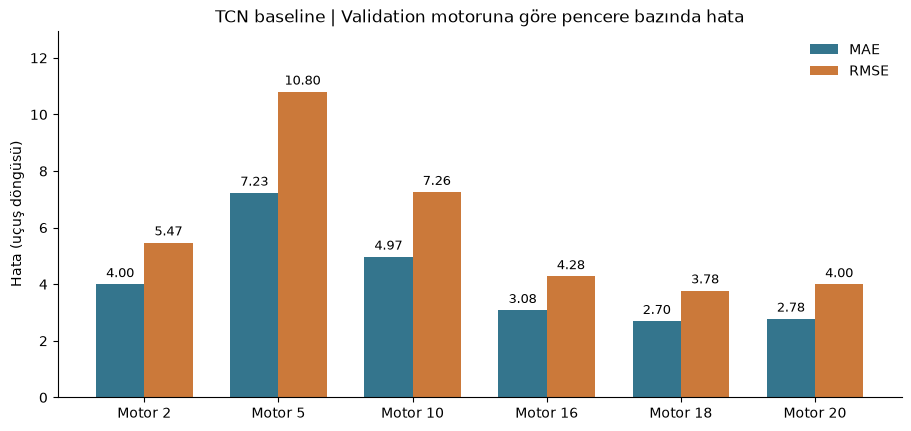

En yüksek iki MAE (döngü): Motor 5 (7.23), Motor 10 (4.97)
En yüksek iki RMSE (döngü): Motor 5 (10.80), Motor 10 (7.26)


In [18]:
import matplotlib.pyplot as plt
import numpy as np

comparison = results.sort_values("Validation motoru").reset_index(drop=True)
x = np.arange(len(comparison))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)

for offset, column, label, color in [
    (-width / 2, "MAE (döngü)", "MAE", "#34758D"),
    ( width / 2, "RMSE (döngü)", "RMSE", "#CB793A"),
]:
    bars = ax.bar(x + offset, comparison[column], width, label=label, color=color)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(x, [f"Motor {m}" for m in comparison["Validation motoru"]])
ax.set_ylabel("Hata (uçuş döngüsü)")
ax.set_title("TCN baseline | Validation motoruna göre pencere bazında hata")
ax.set_ylim(0, comparison["RMSE (döngü)"].max() * 1.2)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

for column in ["MAE (döngü)", "RMSE (döngü)"]:
    highest = comparison.nlargest(2, column)
    ranking = ", ".join(
        f"Motor {int(row['Validation motoru'])} ({row[column]:.2f})"
        for _, row in highest.iterrows()
    )
    print(f"En yüksek iki {column}: {ranking}")

In [ ]:
from functools import lru_cache

import ipywidgets as widgets
import pandas as pd
from IPython.display import display


@lru_cache(maxsize=6)
def load_fold_for_plot(fold):
    # Sonuç tablosuyla aynı kural: metrikleri kaydedilmiş son çalışma.
    files = sorted(runs_dir.glob(f"fold_{fold}_*/metrics.csv"))
    if not files:
        raise FileNotFoundError(f"Fold {fold} için metrics.csv bulunamadı.")

    run_dir = files[-1].parent
    metric = pd.read_csv(run_dir / "metrics.csv").iloc[0]
    history = pd.read_csv(run_dir / "history.csv")
    predictions = pd.read_csv(run_dir / "predictions.csv")

    motor = int(metric["validation_unit"])
    if (
        int(metric["fold"]) != fold
        or set(predictions["unit"]) != {motor}
        or len(predictions) != int(metric["windows"])
    ):
        raise ValueError(f"Fold {fold}: motor veya pencere kayıtları uyuşmuyor.")

    by_flight = predictions.groupby("cycle", sort=True)
    if not by_flight["actual_rul"].nunique().eq(1).all():
        raise ValueError(f"Fold {fold}: aynı uçuşta birden fazla gerçek RUL var.")

    flights = by_flight.agg(
        actual=("actual_rul", "first"),
        predicted=("predicted_rul", "mean"),
        p10=("predicted_rul", lambda values: values.quantile(0.10)),
        p90=("predicted_rul", lambda values: values.quantile(0.90)),
    )
    return metric, history, flights


def plot_fold(fold):
    metric, history, flights = load_fold_for_plot(fold)
    motor = int(metric["validation_unit"])
    best_epoch = int(metric["best_epoch"])
    best = history.loc[history["epoch"] == best_epoch].iloc[0]

    fig, (loss_ax, rul_ax) = plt.subplots(
        1, 2, figsize=(13, 4.3), constrained_layout=True
    )

    # Sol: Her iki eğri de MSE, dolayısıyla aynı eksende karşılaştırılabilir.
    loss_ax.plot(history["epoch"], history["train_mse"],
                 color="#34758D", label="Training MSE")
    loss_ax.plot(history["epoch"], history["validation_mse"],
                 color="#CB793A", label="Validation MSE")
    loss_ax.axvline(best_epoch, color="#52616B", linestyle="--", linewidth=1)
    loss_ax.scatter(best_epoch, best["validation_mse"], color="#24735C",
                    zorder=3, label=f"En iyi epoch: {best_epoch}")
    loss_ax.set(title="Epoch boyunca kayıp", xlabel="Epoch",
                ylabel="MSE (uçuş döngüsü²)")
    loss_ax.legend(frameon=False)

    # Sağ: Her nokta bir uçuş. Bant aynı uçuştaki pencere tahminlerini özetler.
    cycles = flights.index.to_numpy()
    rul_ax.fill_between(
        cycles, flights["p10"].to_numpy(), flights["p90"].to_numpy(),
        color="#CB793A", alpha=0.22, label="Pencere tahminleri: %10–%90",
    )
    rul_ax.plot(cycles, flights["actual"], color="#263D50",
                linewidth=2, label="Gerçek RUL")
    rul_ax.plot(cycles, flights["predicted"], color="#CB793A",
                linewidth=2, label="Uçuş başına ortalama tahmin")
    rul_ax.set(title="Uçuş boyunca kalan ömür", xlabel="Uçuş numarası (cycle)",
               ylabel="RUL (uçuş döngüsü)")
    rul_ax.legend(frameon=False, fontsize=9)

    for ax in (loss_ax, rul_ax):
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(
        f"Fold {fold} · Validation motoru {motor} · "
        f"Pencere MAE {metric['mae']:.2f} · RMSE {metric['rmse']:.2f}"
    )
    plt.show()


selector = widgets.Dropdown(
    options=[
        (f"Fold {int(row['Fold'])} — Motor {int(row['Validation motoru'])}",
         int(row["Fold"]))
        for _, row in results.sort_values("Fold").iterrows()
    ],
    description="Fold:",
)
display(selector, widgets.interactive_output(plot_fold, {"fold": selector}))

Dropdown(description='Fold:', options=(('Fold 1 — Motor 2', 1), ('Fold 2 — Motor 5', 2), ('Fold 3 — Motor 10',…

Output()